# Step 3: Attention model (DIN-style target attention)

**Pipeline.** `step1_data_preprocess.ipynb` → `step2_baselines.ipynb` → `step3_lightgbm.ipynb` / `step3_lambdarank.ipynb` / `step3_attention.ipynb` (this notebook).

**What it does.** For every product in a user's last search, the model re-reads the user's history and asks *which past actions look like this product?* Those actions get most of the weight, so each candidate gets its own user profile (DIN's "target attention"). Team 3's model instead pooled the whole history into one vector for every candidate. The profile goes into one network together with the same 65 features LightGBM uses (the hybrid, model (b)). Ablations then show where any gain comes from.

**Same contract as every other step 3 model:** binary target (label ≥ 1), step 1's user split, full validation slates, the shared metric code (first code cell, copied verbatim from `step3_lightgbm.ipynb`), test scored once, after the group picked the final model (8 Nov).

| # | Decision | Choice |
|---|---|---|
| A1 | Main model | Hybrid (b): DIN-style target attention over the user's history, plus LightGBM's 65 features, in one network |
| A2 | Inputs | `history_full.parquet` (step 1's `H_full`), `features.parquet` (candidate shop/brand/category and the 65 features), `users.parquet`. Sequences start from **all** users in `users.parquet`; users with no history (44 on the full data) get an empty sequence and are still scored |
| A3 | Rows, target, loss | LightGBM's `fit` rows (all positives + 20 random negatives per train slate), binary label, BCE. Early stopping on validation NDCG@10 over full slates, patience 3, at most 30 epochs |
| A4 | History cap | Most recent `WIN_CAPS` = 50 / 30 / 20 actions in the 0–7 / 7–90 / 90–365-day windows (checked against the counts in Section 3). Ablation: plain last 100 |
| A5 | Product vector | category 1–4 embeddings (dropped shop and brand due to overfitting) → one 64-dim vector, shared by history and candidates. Vocabularies from train users only; values seen fewer than `RARE_MIN` = 5 times → "rare"; missing metadata → "unknown". No product-ID embeddings, no name text |
| A6 | Action vector | Product vector + action-type embedding + elapsed-time embedding, 11 buckets: <10 min, 10–30 min, 30 min–1 h, 1–6 h, 6–24 h, 1–3 d, 3–7 d, 7–30 d, 30–90 d, 90–180 d, 180 d+. Edges follow a roughly log scale, with 7 and 90 days fixed at the retention cutoffs found in step 1 and 30 minutes at the session gap |
| A7 | Attention unit | DIN-style activation unit on [candidate, action, difference, element-wise product] plus an exact-match flag → 64 → 1 relevance score. The DIN paper uses the outer product; the difference and element-wise product are the cheaper common variant |
| A8 | Normalisation | Softmax over the history plus a learned "none of these" slot (ZAM's idea; SIM, the DIN team's follow-up, also uses softmax). A deliberate departure from DIN's unnormalised weights, used in both (a) and (b) |
| A9 | Network | [profile, candidate vector, profile ⊙ candidate, 65 prepared features, 2 categorical embeddings] → 256 → 128 → 1, ReLU, dropout 0.2 |
| A10 | Feature prep | log1p on non-negative columns that exceed 1 (counts, days); standardise on `fit` rows; missing → 0 plus a "was missing" flag; clip to ±5 |
| A11 | Optimiser | Adam, learning rate 1e-3, 256 users per batch, gradient-norm clip 1.0, fp16 mixed precision on GPU, seed 42, no hyperparameter search |
| A12 | Ablations | (b) → no-attention control (mean pool) → (a) pure sequence → last 100 → features-only (only if (b) trails LightGBM) → 2×2 with DIN's unnormalised weights (stretch) |
| A13 | Saving | Each run uploads its validation scores, best checkpoint, metrics and training log to `RESULT_FOLDER` on Drive as soon as it finishes, plus the best checkpoint at every improvement. `LOAD_CHECKPOINT` reuses them after a disconnect |
| A14 | Test | `RUN_TEST = True` (8 Nov). After the group picked the final model (LambdaRank), only the main model was scored on test, once, from its saved checkpoint |

## How to run in Colab
1. **Runtime → Change runtime type → T4 GPU (or better), High-RAM.**
2. Sign in with an account that can see the shared `BT4222_artifacts` folder (read by its fixed id). The notebook downloads the step 1 files it needs from it.
3. Runtime → Run all. `MAX_USERS = 0` runs on all users (the saved outputs are this full run). Set it to e.g. 30000 for a quick seeded check of the pipeline; subset scores are for debugging only.
4. Each run uploads its results to `BT4222_step3_attention` in your own My Drive as soon as it finishes. On a rerun, finished runs found there are loaded instead of retrained (`LOAD_CHECKPOINT = True`). The frozen 8 Nov results are in the group folder: `BT4222_step3_attention_val_08Nov` and `BT4222_step3_attention_test_08Nov`.
5. **Save the notebook (File → Save) after each run**, so the printed outputs are kept. Do not clear outputs.

## 1. Setup

The next cell is the first code cell of `step3_lightgbm.ipynb`, copied verbatim, so downloads and metrics are identical to the other models.

In [1]:
import os, sys, json, time, gc
import numpy as np
import pandas as pd
import lightgbm as lgb

IN_COLAB = "google.colab" in sys.modules

# ---- config: change these, nothing else ----
ART_DIR = os.environ.get("JD_ART_DIR", "/content/artifacts" if IN_COLAB else ".")    # step 1 and step 2 files
OUT_DIR = os.environ.get("JD_OUT_DIR", "/content/results" if IN_COLAB else "results") # result tables and the model
DRIVE_ARTIFACT_FOLDER = "BT4222_artifacts"     # folder in your My Drive that steps 1 and 2 copied their files into
SEED = 42
NDCG_GAIN = "linear"                           # must match step 2: "linear" (gain = label) or "exp" (2^label - 1)
RUN_TEST = True                              # keep False until the final run: test is scored once, at the end
RUN_TUNING = False                               # False once the parameters are chosen
# --------------------------------------------
os.makedirs(OUT_DIR, exist_ok=True)

def _drive():
    from google.colab import auth
    auth.authenticate_user()
    from googleapiclient.discovery import build
    return build("drive", "v3")

def _folder_id(svc):
    return "1Yb4AGglIJV4Pdd8Sx6NozG8Klh6uweqH"

def drive_download(names):
    # fetch the named files from My Drive/DRIVE_ARTIFACT_FOLDER into ART_DIR, skipping ones already there
    import io
    from googleapiclient.http import MediaIoBaseDownload
    if not names:
        return
    svc = _drive(); fid = _folder_id(svc); os.makedirs(ART_DIR, exist_ok=True)
    for f in names:
        found = svc.files().list(q=f"'{fid}' in parents and name='{f}' and trashed=false", fields="files(id)").execute()["files"]
        if not found:
            raise FileNotFoundError(f"{f} is not in My Drive/{DRIVE_ARTIFACT_FOLDER}. Run the step that makes it first.")
        with io.FileIO(f"{ART_DIR}/{f}", "wb") as fh:
            dl = MediaIoBaseDownload(fh, svc.files().get_media(fileId=found[0]["id"]), chunksize=100 * 1024 * 1024)
            done = False
            while not done:
                _, done = dl.next_chunk()
        print("downloaded", f)

# Shared metric definitions (src/metrics.py). On Colab without the repo, an identical copy is defined here.
try:
    from src.metrics import MetricAccumulator, bootstrap_ci
except ImportError:
    def _rank(scores, rng):
        # descending score, ties broken uniformly at random (never by stored order: the raw file stores engaged items first)
        return np.lexsort((rng.random(len(scores)), -np.asarray(scores, float)))
    def _metrics(ranked, k, gain):
        g = ranked.astype(float) if gain == "linear" else np.power(2.0, ranked) - 1.0
        rel = np.flatnonzero(ranked > 0)
        disc = 1.0 / np.log2(np.arange(2, k + 2))
        dcg = (g[:k] * disc[: len(g[:k])]).sum()
        ideal = np.sort(g)[::-1][:k]
        idcg = (ideal * disc[: len(ideal)]).sum()
        return {f"hit@{k}": float((ranked[:k] > 0).any()), f"ndcg@{k}": float(dcg / idcg) if idcg > 0 else 0.0,
                "mrr": float(1.0 / (rel[0] + 1)) if len(rel) else 0.0, "p@1": float(ranked[0] > 0)}
    class MetricAccumulator:
        def __init__(self, k=10, gain="linear", seed=42):
            self.k, self.gain, self.rng, self.rows = k, gain, np.random.default_rng(seed), []
        def add(self, scores, labels):
            labels = np.asarray(labels)
            if not (labels > 0).any():
                return None
            m = _metrics(labels[_rank(scores, self.rng)], self.k, self.gain); self.rows.append(m); return m
        def per_slate(self):
            return {key: np.array([r[key] for r in self.rows]) for key in self.rows[0]} if self.rows else {}
    def bootstrap_ci(values, n_boot=1000, alpha=0.05, seed=0):
        values = np.asarray(list(values), float); rng = np.random.default_rng(seed)
        means = values[rng.integers(0, len(values), size=(n_boot, len(values)))].mean(axis=1)
        return float(np.quantile(means, alpha / 2)), float(np.quantile(means, 1 - alpha / 2))

METRICS = ["hit@10", "ndcg@10", "mrr", "p@1"]

def evaluate(df, score):
    """Rank each slate in df (rows grouped by user) by score; one row of metrics per slate."""
    users = df.user.values
    assert (np.diff(users) >= 0).all(), "rows must be grouped by user"
    starts = np.r_[0, np.flatnonzero(np.diff(users)) + 1]; ends = np.r_[starts[1:], len(users)]
    s, y = np.asarray(score, float), df.label.values
    acc, kept = MetricAccumulator(gain=NDCG_GAIN, seed=SEED), []
    for a, b in zip(starts, ends):
        if acc.add(s[a:b], y[a:b]) is not None:
            kept.append(users[a])
    out = pd.DataFrame(acc.per_slate()); out.insert(0, "user", kept)
    return out

def summarise(per, name):
    row = {"model": name, "slates": len(per)}
    row.update({m: per[m].mean() for m in METRICS})
    for m in ["hit@10", "ndcg@10"]:
        lo, hi = bootstrap_ci(per[m]); row[f"{m} 95% CI"] = f"{lo:.3f} to {hi:.3f}"
    return row

FMT = {m: "{:.4f}" for m in METRICS} | {"slates": "{:,}"}
BASELINE_NAMES = {"score_random": "Random", "score_query": "Query only", "score_pop": "Popularity",
                  "score_repeat_pop": "Repeat → popularity", "score_mf": "MF (truncated SVD)",
                  "score_t3_maxprob": "Team 3 NCF (as published: max class prob.)",
                  "score_t3_pengaged": "Team 3 NCF (fixed: P(engaged))"}

### Attention-model settings

Everything this notebook can change is in the next cell. Each file this notebook writes carries a tag (number of users, window caps, rare threshold), so dev runs and full runs never overwrite each other on Drive.

In [2]:
import io, random
import pyarrow.parquet as pq
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

# ---- attention-model config: change these, nothing else ----
OUT_DIR = os.environ.get("JD_OUT_DIR", "/content/results_attn" if IN_COLAB else "results_attn")  # local copies; Drive is the safe copy
RESULT_FOLDER = "BT4222_step3_attention"   # our folder in your My Drive: every run uploads here as soon as it finishes
MAX_USERS = int(os.environ.get("JD_MAX_USERS", 0))   # 30000 = dev run; 0 = all users (needs the team's OK + Colab Pro High-RAM)
LOAD_CHECKPOINT = True                     # reuse prep and finished runs found in RESULT_FOLDER instead of recomputing
WIN_CAPS = (50, 30, 20)                    # A4: latest actions kept in the 0-7 d, 7-90 d, 90-365 d windows (see Section 3)
LAST_N = 100                               # A4 ablation: plain "last 100 actions"
TIME_EDGES_MIN = [10, 30, 60, 6 * 60, 24 * 60, 3 * 1440, 7 * 1440, 30 * 1440, 90 * 1440, 180 * 1440]  # A6: 11 buckets (minutes)
RARE_MIN = 5                               # A5: attribute values seen fewer times among train users -> "rare"
EMB_ATTR, D, ATT_HIDDEN, HEAD, DROPOUT = 16, 64, 64, (256, 128), 0.2      # A5, A7, A9
LR, BATCH_USERS, EVAL_BATCH_USERS, CLIP = 1e-3, 256, 64, 1.0             # A11
MAX_EPOCHS, PATIENCE = 30, 3                                              # A3
RUN_FEATONLY = "auto"                      # A12: "auto" = only if the main model trails LightGBM; True / False to force
RUN_STRETCH = False                        # A12: 2x2 with DIN's unnormalised weights (last in the order)
LAMBDARANK_FILE_ID = "1FD2iUYxEn5zkIJ6JAT4gKhWbxebH3_TZ"                  # Drive file id of LambdaRank's validation scores, once they are shared
ATTN_SAMPLE_USERS = 2000                   # validation users whose attention weights are analysed (Section 11)
# ------------------------------------------------------------
os.makedirs(OUT_DIR, exist_ok=True)
device = "cuda" if torch.cuda.is_available() else "cpu"
AMP = device == "cuda"                     # fp16 mixed precision on GPU only

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)
set_seed(SEED)

DATA_TAG = f"u{MAX_USERS or 'all'}_w{'-'.join(map(str, WIN_CAPS))}_r{RARE_MIN}"
print(f"torch {torch.__version__} | device {device} | tag {DATA_TAG}")
if device == "cuda":
    print(torch.cuda.get_device_name(0), f"{torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

# ---- Drive helpers for OUR results folder (the shared BT4222_artifacts folder is only ever read) ----
_SVC = None
def _svc():
    global _SVC
    if _SVC is None:
        _SVC = _drive()
    return _SVC

_RESULT_FID = None
def _result_folder_id():
    # find My Drive/RESULT_FOLDER, or create it once (never one new folder per run)
    global _RESULT_FID
    if _RESULT_FID is None:
        svc, mime = _svc(), "application/vnd.google-apps.folder"
        q = f"name='{RESULT_FOLDER}' and mimeType='{mime}' and 'root' in parents and trashed=false"
        found = svc.files().list(q=q, fields="files(id)").execute()["files"]
        _RESULT_FID = found[0]["id"] if found else svc.files().create(
            body={"name": RESULT_FOLDER, "mimeType": mime}, fields="id").execute()["id"]
    return _RESULT_FID

def save_to_drive(*names):
    """Upload OUT_DIR/<name> to My Drive/RESULT_FOLDER now, replacing a file of the same name.
    Colab's local disk is wiped on disconnect, so a result counts as saved only once this has run."""
    if not IN_COLAB:
        return
    from googleapiclient.http import MediaFileUpload
    svc, fid = _svc(), _result_folder_id()
    for f in names:
        media = MediaFileUpload(f"{OUT_DIR}/{f}", resumable=True, chunksize=100 * 1024 * 1024)
        old = svc.files().list(q=f"'{fid}' in parents and name='{f}' and trashed=false", fields="files(id)").execute()["files"]
        if old:
            svc.files().update(fileId=old[0]["id"], media_body=media).execute()
        else:
            svc.files().create(body={"name": f, "parents": [fid]}, media_body=media).execute()
        print(f"  uploaded {f} -> My Drive/{RESULT_FOLDER}")

def fetch_from_drive(name):
    """Make sure OUT_DIR/<name> exists, downloading it from My Drive/RESULT_FOLDER if needed. True if it is there."""
    path = f"{OUT_DIR}/{name}"
    if os.path.exists(path):
        return True
    if not IN_COLAB:
        return False
    from googleapiclient.http import MediaIoBaseDownload
    svc, fid = _svc(), _result_folder_id()
    found = svc.files().list(q=f"'{fid}' in parents and name='{name}' and trashed=false", fields="files(id)").execute()["files"]
    if not found:
        return False
    with io.FileIO(path + ".part", "wb") as fh:
        dl = MediaIoBaseDownload(fh, svc.files().get_media(fileId=found[0]["id"]), chunksize=100 * 1024 * 1024)
        done = False
        while not done:
            _, done = dl.next_chunk()
    os.replace(path + ".part", path)
    print(f"  fetched {name} from My Drive/{RESULT_FOLDER}")
    return True

torch 2.14.1+cu130 | device cuda | tag uall_w50-30-20_r5
Tesla T4 15.6 GB


## 2. Load the shared files and check them

All inputs come from the shared `BT4222_artifacts` folder and are only read. The schema checks stop the notebook straight away if a file is not what this notebook expects, instead of failing silently later.

- `features.parquet`: one row per user × candidate, with the candidate's shop, brand and category IDs and LightGBM's 65 features. Test rows are not loaded unless `RUN_TEST = True`.
- `history_full.parquet`: one row per history action (step 1's `H_full`): user, product, action type, days before the search, and the product's shop, brand and category. The 1-second leak guard (step 1, D11) is already applied.
- `lgbm_scores_val.parquet` and `baseline_scores.parquet`: the other models' validation scores, for paired comparisons on exactly the same rows.

In [3]:
SHARED = ["features.parquet", "users.parquet", "config.json", "history_full.parquet",
          "lgbm_scores_val.parquet", "baseline_scores.parquet"]
if IN_COLAB and DRIVE_ARTIFACT_FOLDER:
    drive_download([f for f in SHARED if not os.path.exists(f"{ART_DIR}/{f}")])
cfg = json.load(open(f"{ART_DIR}/config.json"))
FEATURES = [c for c in cfg["FEATURES"] if c != "slate_len"]     # LightGBM's 65 (step 3 drops slate_len)
assert len(FEATURES) == 65, "the feature list must stay at LightGBM's 65"
CAT_FEATURES = ["item_last_type", "cand_cate1"]
NUM_FEATURES = [c for c in FEATURES if c not in CAT_FEATURES]
ATTRS = ["shop_id", "brand_id", "cate_id_1", "cate_id_2", "cate_id_3", "cate_id_4"]
WIN_EDGES = cfg["WIN_EDGES"]                                     # [7, 90] days (step 1, D6)
WIN_NAMES = ["0-7d", "7-90d", "90-365d"]
FULL = MAX_USERS == 0 and cfg["MAX_USERS"] == 0                  # full-data run: exact counts are checked

NEED = {"features.parquet": list(dict.fromkeys(["user", "wid", "label", "split", "fit", "train_eval", "pop_w0", "pop_w1", "pop_w2"] + ATTRS + FEATURES)),
        "users.parquet": ["user", "split", "user_hist_len"],
        "history_full.parquet": ["user", "wid", "t", "days"] + ATTRS,
        "lgbm_scores_val.parquet": ["user", "wid", "split", "label", "score_lgbm"],
        "baseline_scores.parquet": ["user", "wid", "split", "label", "score_repeat_pop", "score_t3_pengaged"]}
SCHEMA = {f: pq.read_schema(f"{ART_DIR}/{f}").names for f in NEED}
for f, cols in NEED.items():
    missing = [c for c in cols if c not in SCHEMA[f]]
    assert not missing, f"{f} is missing columns {missing}: tell the group before going on"
print("history_full.parquet columns:", SCHEMA["history_full.parquet"])

U = pd.read_parquet(f"{ART_DIR}/users.parquet").sort_values("user").reset_index(drop=True)
n_users = len(U)
assert n_users == cfg["n_users"] and (U.user.values == np.arange(n_users)).all(), "users.parquet must hold users 0..n-1"
SPLIT_OF = U.split.values

# dev run: a seeded random sample of users across all three splits (never the first N rows of the file)
if MAX_USERS:
    KEEP_USERS = np.sort(np.random.default_rng(SEED).choice(n_users, size=min(MAX_USERS, n_users), replace=False))
    UFILT = [("user", "in", KEEP_USERS.tolist())]
else:
    KEEP_USERS, UFILT = np.arange(n_users), []
print(f"users: {len(KEEP_USERS):,} of {n_users:,} |", pd.Series(SPLIT_OF[KEEP_USERS]).map({0: "train", 1: "val", 2: "test"}).value_counts().to_dict())

t0 = time.time()
K = pd.read_parquet(f"{ART_DIR}/features.parquet", columns=NEED["features.parquet"],
                    filters=(UFILT + ([] if RUN_TEST else [("split", "!=", 2)])) or None)
assert (np.diff(K.user.values) >= 0).all(), "features.parquet rows must be grouped by user"
hcols = NEED["history_full.parquet"] + (["win"] if "win" in SCHEMA["history_full.parquet"] else [])
H = pd.read_parquet(f"{ART_DIR}/history_full.parquet", columns=hcols, filters=UFILT or None)
print(f"features rows {len(K):,} | history actions {len(H):,} | {time.time() - t0:.0f}s")

# history must be grouped by user, oldest action first; restore that order if the export changed it
u_h, d_h = H.user.values, H.days.values
ordered = (np.diff(u_h) >= 0).all() and not ((np.diff(u_h) == 0) & (np.diff(d_h) > 1e-4)).any()
if not ordered:
    print("history_full.parquet was not in (user, oldest first) order: sorting it")
    H = H.sort_values(["user", "days"], ascending=[True, False], kind="stable").reset_index(drop=True)
win = np.digitize(H.days.values, WIN_EDGES).astype(np.int8)
if "win" in H.columns:
    assert (H.win.values == win).all(), "history 'win' does not match days and WIN_EDGES"
H["win"] = win
assert H.t.isin([0, 1, 2, 3]).all(), "action types must be step 1's codes 0 CLICK, 1 CART, 2 FLW, 3 ORD"

hist_len = np.bincount(H.user.values, minlength=n_users)
n_empty = int((hist_len[KEEP_USERS] == 0).sum())
print(f"users with no history actions: {n_empty:,} (they get an empty sequence and are still scored)")
if FULL:
    assert len(U) == 171_728 and len(H) == 26_375_642, "history_full.parquet is not the full step 1 history"
    assert n_empty == 44, f"expected 44 users without history, found {n_empty}"

LG = pd.read_parquet(f"{ART_DIR}/lgbm_scores_val.parquet", columns=["user", "wid", "score_lgbm"], filters=UFILT or None)
BCOLS = [c for c in SCHEMA["baseline_scores.parquet"] if c.startswith("score_")]
BS = pd.read_parquet(f"{ART_DIR}/baseline_scores.parquet", columns=["user", "wid"] + BCOLS,
                     filters=UFILT + [("split", "==", 1)])
print(f"LightGBM validation rows {len(LG):,} | baseline validation rows {len(BS):,}")

downloaded features.parquet
downloaded users.parquet
downloaded config.json
downloaded history_full.parquet
downloaded lgbm_scores_val.parquet
downloaded baseline_scores.parquet
history_full.parquet columns: ['user', 'wid', 't', 'days', 'has_q', 'gap_before', 'win', 'shop_id', 'brand_id', 'cate_id_1', 'cate_id_2', 'cate_id_3', 'cate_id_4']
users: 171,728 of 171,728 | {'train': 137380, 'test': 17176, 'val': 17172}
features rows 6,690,773 | history actions 26,375,642 | 2s
users with no history actions: 44 (they get an empty sequence and are still scored)
LightGBM validation rows 1,538,177 | baseline validation rows 1,538,177


## 3. Data checks before fixing the settings

Two cheap checks, both on **train users only**, so the settings are chosen without looking at validation:

1. **Window caps (A4).** How many actions does each user have in each window, and how many users would the 50 / 30 / 20 caps cut? Rule we agreed: if almost nobody has more than 20 actions in 90–365 days, that cap is fine; if many users exceed 50 in 0–7 days, consider raising it. The last rows show how much of each window a plain "last 100" keeps, which is what the cap ablation compares.
2. **Rare values (A5).** How many shop, brand and category values are seen fewer than `RARE_MIN` times among train users, and how many validation candidates end up in the "rare / unseen" bucket.

In [4]:
tr_mask_h = SPLIT_OF[H.user.values] == 0
tr_users = KEEP_USERS[SPLIT_OF[KEEP_USERS] == 0]
cnt = np.bincount(H.user.values[tr_mask_h] * 3 + H.win.values[tr_mask_h], minlength=n_users * 3).reshape(n_users, 3)[tr_users]
from_end_all = H.groupby("user").cumcount(ascending=False).to_numpy()      # 0 = most recent action
rows = []
for w, cap in enumerate(WIN_CAPS):
    c = cnt[:, w]; has = c[c > 0]
    in_last = ((from_end_all < LAST_N) & (H.win.values == w) & tr_mask_h).sum()
    rows.append({"window": WIN_NAMES[w], "cap": cap, "users with any": f"{(c > 0).mean():.1%}",
                 "median (users with any)": int(np.median(has)) if has.size else 0,
                 "p90": int(np.percentile(has, 90)) if has.size else 0, "p99": int(np.percentile(has, 99)) if has.size else 0,
                 "users over cap": f"{(c > cap).mean():.1%}",
                 "actions kept, per-window cap": f"{np.minimum(c, cap).sum() / max(c.sum(), 1):.1%}",
                 f"actions kept, last {LAST_N}": f"{in_last / max(c.sum(), 1):.1%}"})
WINDOW_CHECK = pd.DataFrame(rows).set_index("window")
display(WINDOW_CHECK)
tot = cnt.sum(axis=1)
print(f"train users with more than {LAST_N} actions in total: {(tot > LAST_N).mean():.1%} "
      f"(the only users for whom the two caps differ much)")
WINDOW_CHECK.to_csv(f"{OUT_DIR}/attn_window_check_{DATA_TAG}.csv")

,cap,users with any,median (users with any),p90,p99,users over cap,"actions kept, per-window cap","actions kept, last 100"
window,,,,,,,,
0-7d,50,88.1%,28,159,517,30.5%,44.5%,64.2%
7-90d,30,93.3%,34,184,553,49.7%,29.4%,33.7%
90-365d,20,78.2%,15,90,268,32.9%,36.3%,20.6%


train users with more than 100 actions in total: 42.7% (the only users for whom the two caps differ much)


In [5]:
# vocabulary per attribute, from train users only: their history actions + their training (fit) candidates
fit_tr = K.fit.values
VOCAB, rows = {}, []
for a in ATTRS:
    vals = np.concatenate([H[a].values[tr_mask_h], K[a].values[fit_tr]]).astype(np.int64)
    vals = vals[vals > 0]                                         # -1 = no metadata, never a vocabulary entry
    vc = pd.Series(vals).value_counts()
    VOCAB[a] = pd.Index(np.sort(vc.index.values[vc.values >= RARE_MIN]))
    va = K[a].values[K.split.values == 1]
    rows.append({"attribute": a, "distinct values (train)": len(vc), f"seen < {RARE_MIN} times": int((vc < RARE_MIN).sum()),
                 f"share of distinct values < {RARE_MIN}": f"{(vc < RARE_MIN).mean():.1%}",
                 "share of train occurrences they cover": f"{vc[vc < RARE_MIN].sum() / vc.sum():.2%}",
                 "vocabulary size": len(VOCAB[a]),
                 "val candidates -> rare/unseen": f"{((va > 0) & (VOCAB[a].get_indexer(va) < 0)).mean():.1%}",
                 "val candidates -> unknown": f"{(va <= 0).mean():.1%}"})
RARE_CHECK = pd.DataFrame(rows).set_index("attribute")
display(RARE_CHECK)
RARE_CHECK.to_csv(f"{OUT_DIR}/attn_rare_check_{DATA_TAG}.csv")
save_to_drive(f"attn_window_check_{DATA_TAG}.csv", f"attn_rare_check_{DATA_TAG}.csv")

,distinct values (train),seen < 5 times,share of distinct values < 5,share of train occurrences they cover,vocabulary size,val candidates -> rare/unseen,val candidates -> unknown
attribute,,,,,,,
shop_id,229515,54160,23.6%,0.52%,175355,2.6%,1.5%
brand_id,156274,50203,32.1%,0.45%,106071,1.9%,0.5%
cate_id_1,73,7,9.6%,0.00%,66,0.0%,0.5%
cate_id_2,649,66,10.2%,0.00%,583,0.0%,0.5%
cate_id_3,5559,642,11.5%,0.01%,4917,0.0%,0.5%
cate_id_4,6822,752,11.0%,0.01%,6070,0.0%,0.5%


  uploaded attn_window_check_uall_w50-30-20_r5.csv -> My Drive/BT4222_step3_attention
  uploaded attn_rare_check_uall_w50-30-20_r5.csv -> My Drive/BT4222_step3_attention


## 4. Build the sequences, the product table and the features

**Product table.** Every product that appears as a candidate or in a kept history action gets one row holding its six attribute indices (0 = padding, 1 = unknown, 2 = rare or unseen, 3+ = vocabulary). History and candidates then point into the same table, so the shared product encoder sees them identically, and "same product" is simply "same row" (the exact-match flag, A7). No product-ID embedding is learned.

**Sequences.** One row per user in `users.parquet` (all of them, A2), holding the kept actions oldest first: product row, action type (1 click, 2 cart, 3 follow, 4 order) and elapsed-time bucket (1–11). Two versions: per-window caps (main model) and last 100 (ablation).

The prep is saved to Drive once, so a disconnect never forces it to rerun.

In [6]:
TIME_EDGES_DAYS = np.array(TIME_EDGES_MIN, dtype=np.float64) / 1440
TIME_NAMES = ["<10m", "10-30m", "30m-1h", "1-6h", "6-24h", "1-3d", "3-7d", "7-30d", "30-90d", "90-180d", "180d+"]
TYPE_NAMES = ["CLICK", "CART", "FLW", "ORD"]
assert len(TIME_NAMES) == len(TIME_EDGES_DAYS) + 1 == 11

def time_bucket(days):
    return (np.digitize(days, TIME_EDGES_DAYS) + 1).astype(np.int8)      # 1..11; 0 = padding

def encode_attr(a, vals):
    vals = np.asarray(vals, dtype=np.int64)
    out = VOCAB[a].get_indexer(vals).astype(np.int64) + 3                  # not in vocabulary -> -1 + 3 = 2 (rare / unseen)
    out[vals <= 0] = 1                                                     # no metadata -> unknown
    return out

PREP_FILE = f"attn_prep_{DATA_TAG}{'_test' if RUN_TEST else ''}.npz"
t0 = time.time()
if LOAD_CHECKPOINT and fetch_from_drive(PREP_FILE):
    z = np.load(f"{OUT_DIR}/{PREP_FILE}")
    PROD_ATTR, CAND_PROD = z["prod_attr"], z["cand_prod"]
    SEQS = {s: {k: z[f"{s}_{k}"] for k in ["prod", "type", "time", "len"]} for s in ["win", "last"]}
    assert len(CAND_PROD) == len(K), "saved prep does not match the loaded rows: delete it on Drive and rerun"
    print(f"loaded {PREP_FILE}")
else:
    from_end_win = H.groupby(["user", "win"]).cumcount(ascending=False).to_numpy()
    SEL = {"win": from_end_win < np.array(WIN_CAPS)[H.win.values], "last": from_end_all < LAST_N}
    used = SEL["win"] | SEL["last"]
    tab = pd.concat([K[["wid"] + ATTRS], H.loc[used, ["wid"] + ATTRS]], ignore_index=True)
    tab = tab.drop_duplicates("wid").sort_values("wid").reset_index(drop=True)
    PROD_WID = tab.wid.values
    PROD_ATTR = np.zeros((len(tab) + 1, len(ATTRS)), np.int32)             # row 0 = padding product
    for j, a in enumerate(ATTRS):
        PROD_ATTR[1:, j] = encode_attr(a, tab[a].values)
    prod_row = lambda w: (np.searchsorted(PROD_WID, w) + 1).astype(np.int32)
    CAND_PROD = prod_row(K.wid.values)
    SEQS = {}
    for s, L in [("win", sum(WIN_CAPS)), ("last", LAST_N)]:
        h = H[SEL[s]]
        u = h.user.values
        pos = h.groupby("user").cumcount().to_numpy()                       # 0 = oldest kept action
        SEQS[s] = {"prod": np.zeros((n_users, L), np.int32), "type": np.zeros((n_users, L), np.int8),
                   "time": np.zeros((n_users, L), np.int8), "len": np.bincount(u, minlength=n_users).astype(np.int16)}
        SEQS[s]["prod"][u, pos] = prod_row(h.wid.values)
        SEQS[s]["type"][u, pos] = h.t.values.astype(np.int8) + 1
        SEQS[s]["time"][u, pos] = time_bucket(h.days.values)
        del h, u, pos
    np.savez_compressed(f"{OUT_DIR}/{PREP_FILE}", prod_attr=PROD_ATTR, cand_prod=CAND_PROD,
                        **{f"{s}_{k}": v for s in SEQS for k, v in SEQS[s].items()})
    save_to_drive(PREP_FILE)
    del tab, from_end_win, SEL, used
ATTR_SIZES = [len(VOCAB[a]) + 3 for a in ATTRS]
for s in SEQS:
    L = SEQS[s]["len"][KEEP_USERS]
    print(f"sequences '{s}': up to {SEQS[s]['prod'].shape[1]} actions, mean kept {L.mean():.1f}, empty {(L == 0).sum():,} users")
print(f"product table {len(PROD_ATTR) - 1:,} products | vocabulary sizes {dict(zip(ATTRS, ATTR_SIZES))} | {time.time() - t0:.0f}s")

  uploaded attn_prep_uall_w50-30-20_r5_test.npz -> My Drive/BT4222_step3_attention
sequences 'win': up to 100 actions, mean kept 55.5, empty 44 users
sequences 'last': up to 100 actions, mean kept 65.3, empty 44 users
product table 6,750,405 products | vocabulary sizes {'shop_id': 175358, 'brand_id': 106074, 'cate_id_1': 69, 'cate_id_2': 586, 'cate_id_3': 4920, 'cate_id_4': 6073} | 53s


### The 65 features, prepared for a neural network (A10)

Trees do not care about scale or blanks; a neural network does. Each numeric feature is: log1p-transformed if it is non-negative and goes above 1 (counts and days, which are heavily skewed); standardised with the mean and spread of the `fit` rows; set to 0 where it was blank, with a separate "was missing" flag for every column that has blanks; clipped to ±5. The two categorical features get small embeddings: `item_last_type` (none / click / cart / follow / order) and `cand_cate1`, which step 1 built from `cate_id_1`, so it is encoded with the same level-1 category vocabulary.

In [7]:
t0 = time.time()
fit_rows_mask = K.fit.values
DENSE_COLS, MISS_COLS, LOG_COLS, STATS = [], [], [], {}
blocks = []
for c in NUM_FEATURES:
    x = K[c].to_numpy(np.float32)
    xf = x[fit_rows_mask]
    if np.nanmin(xf) >= 0 and np.nanmax(xf) > 1:
        x = np.log1p(np.maximum(x, 0)); LOG_COLS.append(c); xf = x[fit_rows_mask]
    mu, sd = float(np.nanmean(xf)), float(np.nanstd(xf)) or 1.0
    STATS[c] = (mu, sd)
    miss = np.isnan(x)
    z = np.clip(np.nan_to_num((x - mu) / sd, nan=0.0), -5, 5)
    blocks.append(z.astype(np.float16))
    if np.isnan(xf).any():
        blocks.append(miss.astype(np.float16)); MISS_COLS.append(c)
DENSE = np.stack(blocks, axis=1)
del blocks
ilt = K["item_last_type"].astype(str).to_numpy()
CATS = np.stack([pd.Categorical(ilt, categories=["none"] + TYPE_NAMES).codes + 1,          # 0 = unexpected value
                 encode_attr("cate_id_1", K["cate_id_1"].values)], axis=1).astype(np.int64)
assert (K["cand_cate1"].astype("float64").fillna(-1).values == K["cate_id_1"].values).all(), "cand_cate1 should equal cate_id_1"
N_DENSE = DENSE.shape[1]
print(f"{len(NUM_FEATURES)} numeric features ({len(LOG_COLS)} log1p-transformed) + {len(MISS_COLS)} missing flags = {N_DENSE} inputs | "
      f"{DENSE.nbytes / 1e9:.2f} GB | {time.time() - t0:.0f}s")

# keep only what later cells need, to free memory
KM = K[["user", "wid", "label", "split", "fit", "train_eval", "pop_w0", "pop_w1", "pop_w2"]].copy()
del K, ilt; gc.collect()

63 numeric features (41 log1p-transformed) + 40 missing flags = 103 inputs | 1.38 GB | 20s


1995

## 5. Batches

A batch is a group of users. For each user it holds their candidates (padded to the longest slate in the batch) and their history sequence. Training batches use the `fit` rows; scoring uses full slates (validation users, and the 10,000 `train_eval` users for training performance, as in LightGBM).

In [8]:
ROW_USER, LABEL = KM.user.values, KM.label.values.astype(np.int64)

def user_groups(mask):
    """Users and their row positions for the rows in mask (rows are grouped by user, so each user's rows are contiguous)."""
    idx = np.flatnonzero(mask)
    users, start = np.unique(ROW_USER[idx], return_index=True)
    return users, np.split(idx, start[1:])

def batches(users, rows, size, shuffle=False, seed=SEED):
    order = np.random.default_rng(seed).permutation(len(users)) if shuffle else np.arange(len(users))
    for s in range(0, len(order), size):
        sel = order[s: s + size]
        yield users[sel], [rows[i] for i in sel]

def make_batch(users, rows, seq):
    C = max(len(r) for r in rows)
    idx = np.full((len(users), C), -1, np.int64)
    for j, r in enumerate(rows):
        idx[j, :len(r)] = r
    valid = idx >= 0
    safe = np.where(valid, idx, 0)
    L = max(int(seq["len"][users].max()), 1)
    b = {"cand": np.where(valid, CAND_PROD[safe], 0), "dense": DENSE[safe], "cats": CATS[safe],
         "label": np.where(valid, LABEL[safe], -1),
         "h_prod": seq["prod"][users, :L], "h_type": seq["type"][users, :L], "h_time": seq["time"][users, :L],
         "h_len": seq["len"][users]}
    out = {}
    for k, v in b.items():
        t = torch.from_numpy(np.ascontiguousarray(v))
        out[k] = (t if k == "dense" else t.long()).to(device, non_blocking=True)
    return out

FIT = user_groups(KM.fit.values)
VAL = user_groups(KM.split.values == 1)
TRE = user_groups((KM.split.values == 0) & KM.train_eval.values)
print(f"train: {len(FIT[0]):,} users, {KM.fit.sum():,} rows | validation: {len(VAL[0]):,} users, full slates | "
      f"train_eval: {len(TRE[0]):,} users, full slates")
print(f"largest slate: training {max(len(r) for r in FIT[1])}, validation {max(len(r) for r in VAL[1])} candidates")

train: 137,380 users, 2,937,620 rows | validation: 17,172 users, full slates | train_eval: 10,000 users, full slates
largest slate: training 72, validation 200 candidates


## 6. The model

Three parts, each kept small so it can be explained:

1. **`ProductEncoder`**: category 1–4 embeddings (dropped shop and brand embeddings due to overfitting), joined and projected to one 64-dim vector. The same encoder describes history products and candidates, so attention can compare them.
2. **`TargetAttention`** (DIN's activation unit): for every (candidate, past action) pair, a tiny network reads [candidate, action, difference, element-wise product, exact-match flag] and outputs one relevance score. The action vector already contains the action type and the time bucket, so the unit can learn rules such as "a same-brand cart 2 hours ago matters more than a same-brand click 6 days ago". The first layer is computed part by part (the same maths as one layer on the joined input), so the large [candidates × actions × 256] input is never built in GPU memory.
3. **`UserInterest`**: turns the scores into weights and the weighted sum of actions into the candidate's profile.
   - `softmax_slot` (main): softmax over the history plus a learned "none of these" slot. If nothing in the history resembles the candidate, most weight goes to the slot and the profile becomes neutral. Users with no history get only the slot.
   - `din` (stretch ablation): DIN's raw, unnormalised weights.
   - `meanpool` (no-attention control): the plain average of the history, the same for every candidate (like team 3's pooling).

The network then scores [profile, candidate, profile ⊙ candidate] together with the prepared 65 features (`hybrid`), or without them (`pure`, model (a)), or only the features (`featonly`).

In [9]:
# Test without candidate embedding
# Drop shop and brand embeddings to check overfitting
class ProductEncoder(nn.Module):
    def __init__(self, sizes, cols=None):
        super().__init__()
        self.cols = list(range(len(sizes))) if cols is None else list(cols)   # default: all 6 attributes (unchanged)
        self.embs = nn.ModuleList([nn.Embedding(sizes[i], EMB_ATTR, padding_idx=0) for i in self.cols])
        self.proj = nn.Linear(EMB_ATTR * len(self.cols), D)
    def forward(self, attr):                                   # attr: [..., 6] attribute indices
        return self.proj(torch.cat([e(attr[..., i]) for i, e in zip(self.cols, self.embs)], dim=-1))

class TargetAttention(nn.Module):
    """DIN-style activation unit. score(q, k) = w_out . relu(Wq q + Wk k + Wd (q - k) + Wp (q * k) + w_m * match) + b"""
    def __init__(self):
        super().__init__()
        self.wq = nn.Linear(D, ATT_HIDDEN)
        self.wk = nn.Linear(D, ATT_HIDDEN, bias=False)
        self.wd = nn.Linear(D, ATT_HIDDEN, bias=False)
        self.wp = nn.Parameter(torch.randn(ATT_HIDDEN, D) / D ** 0.5)
        self.w_match = nn.Parameter(torch.zeros(ATT_HIDDEN))
        self.out = nn.Linear(ATT_HIDDEN, 1)
    def forward(self, q, k, match):                            # q [B,C,D], k [B,L,D], match [B,C,L]
        k = k.to(q.dtype)
        a = self.wq(q) + self.wd(q)                            # parts that depend on the candidate only   [B,C,H]
        b = (self.wk(k) - self.wd(k)).to(a.dtype)              # parts that depend on the action only      [B,L,H]
        q, k = q.to(a.dtype), k.to(a.dtype)
        p = torch.einsum("bcd,hd,bld->bclh", q, self.wp.to(a.dtype), k)   # element-wise product term      [B,C,L,H]
        h = F.relu(a[:, :, None] + b[:, None] + p + match[..., None].to(a.dtype) * self.w_match.to(a.dtype))
        return self.out(h).squeeze(-1)                         # relevance score per (candidate, action)   [B,C,L]

class UserInterest(nn.Module):
    def __init__(self, mode="softmax_slot"):
        super().__init__()
        assert mode in ("softmax_slot", "din", "meanpool")
        self.mode = mode
        self.none_slot = nn.Parameter(torch.randn(D) * 0.02)  # learned "none of these" action (meanpool: the empty-history profile)
        self.att = TargetAttention() if mode != "meanpool" else None
    def forward(self, q, k, mask, match):                      # mask [B,L]: real actions
        B, C, _ = q.shape
        if self.mode == "meanpool":
            m = mask.to(k.dtype)[..., None]
            n = m.sum(1)
            mean = (k * m).sum(1) / n.clamp(min=1)
            p = torch.where(n > 0, mean, self.none_slot.to(k.dtype).expand_as(mean))
            return p[:, None].expand(-1, C, -1), None
        if self.mode == "softmax_slot":
            k = torch.cat([k, self.none_slot.to(k.dtype).expand(B, 1, -1)], dim=1)
            mask = torch.cat([mask, torch.ones_like(mask[:, :1])], dim=1)
            match = torch.cat([match, torch.zeros_like(match[..., :1])], dim=-1)
        s = self.att(q, k, match).float()
        if self.mode == "softmax_slot":
            w = torch.softmax(s.masked_fill(~mask[:, None], float("-inf")), dim=-1)
        else:
            w = s * mask[:, None]                              # DIN: raw weights, no normalisation
        return torch.einsum("bcl,bld->bcd", w.to(k.dtype), k), w

# Add cand_emb option
class AttnRanker(nn.Module):
    def __init__(self, arch="hybrid", mode="softmax_slot", cand_emb=None, prod_attrs=None):
        super().__init__()
        assert arch in ("hybrid", "pure", "featonly")
        self.arch = arch
        self.cand_emb = (arch != "featonly") if cand_emb is None else cand_emb
        if arch != "featonly" or self.cand_emb:
            cols = None if prod_attrs is None else [ATTRS.index(a) for a in prod_attrs]
            self.prod = ProductEncoder(ATTR_SIZES, cols)
        if arch != "featonly":
            self.type_emb = nn.Embedding(5, D, padding_idx=0)
            self.time_emb = nn.Embedding(12, D, padding_idx=0)
            self.interest = UserInterest(mode)
        n_in = 0 if arch == "featonly" else 2 * D          # profile, profile * candidate
        n_in += D if self.cand_emb else 0                   # raw candidate embedding

        if arch != "pure":
            self.last_type_emb = nn.Embedding(6, 8)
            self.cate1_emb = nn.Embedding(ATTR_SIZES[ATTRS.index("cate_id_1")], 8)
            n_in += N_DENSE + 16
        layers, d_in = [], n_in
        for h in HEAD:
            layers += [nn.Linear(d_in, h), nn.ReLU(), nn.Dropout(DROPOUT)]; d_in = h
        self.head = nn.Sequential(*layers, nn.Linear(d_in, 1))
        self.register_buffer("prod_attr", torch.zeros(1, len(ATTRS), dtype=torch.int32), persistent=False)

    def set_products(self, prod_attr):                          # product table lives on the GPU but is not a weight
        self.prod_attr = torch.as_tensor(prod_attr, dtype=torch.int32, device=device)

    def forward(self, b, return_weights=False):
        parts, w = [], None
        if self.arch != "featonly" or self.cand_emb:
            c = self.prod(self.prod_attr[b["cand"]].long())                     # candidates [B,C,D]
        if self.arch != "featonly":
            k = (self.prod(self.prod_attr[b["h_prod"]].long()) + self.type_emb(b["h_type"])
                 + self.time_emb(b["h_time"])).to(c.dtype)
            mask = torch.arange(k.size(1), device=k.device)[None] < b["h_len"][:, None]
            match = (b["cand"][:, :, None] == b["h_prod"][:, None, :]) & mask[:, None]
            p, w = self.interest(c, k, mask, match)
            parts += [p, p * c]
        if self.cand_emb:
            parts += [c]
        if self.arch != "pure":
            parts += [b["dense"].to(parts[0].dtype if parts else torch.float32),
                      self.last_type_emb(b["cats"][..., 0]), self.cate1_emb(b["cats"][..., 1])]
        x = torch.cat([t.to(parts[0].dtype) for t in parts], dim=-1)
        logit = self.head(x).squeeze(-1)
        return (logit, w) if return_weights else logit

PROD_T = torch.as_tensor(PROD_ATTR, dtype=torch.int32, device=device)   # one shared copy of the product table on the GPU
for arch in ["hybrid", "pure", "featonly"]:
    print(f"{arch:9s} parameters: {sum(p.numel() for p in AttnRanker(arch).parameters()):,}")

hybrid    parameters: 4,826,714
pure      parameters: 4,795,650
featonly  parameters: 64,345


## 7. Training and scoring

`run_variant` trains one model and saves everything about it to Drive:
- **During training**, after every epoch it scores the full validation slates with the shared `evaluate` and keeps the epoch with the best NDCG@10. Each time it improves, the checkpoint (model, optimiser, epoch, log) is uploaded, so a disconnect loses at most the epochs since the last improvement and training resumes from there. Training stops after `PATIENCE` epochs without improvement.
- **When a run finishes**, its validation scores (`user, wid, split, label, score_…`), best checkpoint, metrics (train vs validation) and training log are uploaded straight away.
- **On a rerun** with `LOAD_CHECKPOINT = True`, a finished run is loaded from Drive instead of retrained; an unfinished one resumes from its last uploaded checkpoint.

Training performance is measured like LightGBM's: on the 10,000 `train_eval` users' full slates. A large train-vs-validation gap means overfitting; the first fixes are more dropout or smaller embeddings, not a search.

In [10]:
RUNS = {}
amp_ctx = lambda: torch.autocast(device_type="cuda", dtype=torch.float16, enabled=AMP)

@torch.no_grad()
def score_rows(model, groups, seq):
    """Scores for every row in groups, in row order (the order evaluate() needs)."""
    model.eval()
    users, rows = groups
    out = np.empty(sum(len(r) for r in rows), np.float32); pos = 0
    for bu, br in batches(users, rows, EVAL_BATCH_USERS):
        with amp_ctx():
            lg = model(make_batch(bu, br, seq)).float().cpu().numpy()
        for j, r in enumerate(br):
            out[pos: pos + len(r)] = lg[j, :len(r)]; pos += len(r)
    return out

def rows_df(groups):
    return KM.iloc[np.concatenate(groups[1])][["user", "wid", "split", "label"]].reset_index(drop=True)

def score_col(name):
    return "score_attn" if name == "main" else f"score_attn_{name}"

def run_variant(name, arch="hybrid", mode="softmax_slot", seq_name="win", cand_emb=None, prod_attrs=None):
    tag = f"{name}_{DATA_TAG}"
    f_ckpt, f_scores = f"attn_{tag}_best.pt", f"attn_{tag}_scores_val.parquet"
    f_metrics, f_log = f"attn_{tag}_metrics.csv", f"attn_{tag}_log.csv"
    seq = SEQS[seq_name]
    set_seed(SEED)
    model = AttnRanker(arch, mode, cand_emb, prod_attrs).to(device); model.set_products(PROD_T)
    if device == "cuda":
        torch.cuda.reset_peak_memory_stats()
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    scaler = torch.amp.GradScaler("cuda", enabled=AMP)
    start, best, best_epoch, log = 0, -1.0, 0, []
    finished = LOAD_CHECKPOINT and all(fetch_from_drive(f) for f in [f_metrics, f_scores, f_ckpt])
    if LOAD_CHECKPOINT and fetch_from_drive(f_ckpt):
        st = torch.load(f"{OUT_DIR}/{f_ckpt}", map_location=device, weights_only=False)
        model.load_state_dict(st["model"]); opt.load_state_dict(st["opt"]); scaler.load_state_dict(st["scaler"])
        start, best, best_epoch, log = st["epoch"], st["best"], st["epoch"], st["log"]
        if finished and fetch_from_drive(f_log):
            log = pd.read_csv(f"{OUT_DIR}/{f_log}").to_dict("records")
        print(f"[{name}] {'finished run loaded' if finished else 'resuming after epoch ' + str(start)} from {f_ckpt}")
    t_run = time.time()
    if not finished:
        bad = 0
        for epoch in range(start, MAX_EPOCHS):
            model.train(); t0, tot, n = time.time(), 0.0, 0
            for bu, br in batches(*FIT, BATCH_USERS, shuffle=True, seed=SEED + epoch):
                b = make_batch(bu, br, seq)
                with amp_ctx():
                    logit = model(b)
                m = b["label"] >= 0
                loss = F.binary_cross_entropy_with_logits(logit.float()[m], (b["label"][m] > 0).float())
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward(); scaler.unscale_(opt)
                nn.utils.clip_grad_norm_(model.parameters(), CLIP)
                scaler.step(opt); scaler.update()
                tot += loss.item(); n += 1
            per = evaluate(rows_df(VAL), score_rows(model, VAL, seq))
            row = {"epoch": epoch + 1, "train_loss": tot / max(n, 1), "val_hit@10": float(per["hit@10"].mean()),
                   "val_ndcg@10": float(per["ndcg@10"].mean()), "seconds": round(time.time() - t0, 1)}
            if device == "cuda":
                row["peak_gpu_gb"] = round(torch.cuda.max_memory_allocated() / 1e9, 2)
            log.append(row)
            improved = row["val_ndcg@10"] > best
            print(f"[{name}] epoch {epoch + 1}: loss {row['train_loss']:.4f} | val Hit@10 {row['val_hit@10']:.4f} | "
                  f"val NDCG@10 {row['val_ndcg@10']:.4f} | {row['seconds']:.0f}s" + (" | best so far" if improved else ""))
            if improved:
                best, best_epoch, bad = row["val_ndcg@10"], epoch + 1, 0
                torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "scaler": scaler.state_dict(),
                            "epoch": epoch + 1, "best": best, "log": log,
                            "config": {"arch": arch, "mode": mode, "seq": seq_name, "tag": DATA_TAG}}, f"{OUT_DIR}/{f_ckpt}")
                save_to_drive(f_ckpt)
            else:
                bad += 1
                if bad >= PATIENCE:
                    print(f"[{name}] no gain for {PATIENCE} epochs: stopping, best epoch {best_epoch}")
                    break
        st = torch.load(f"{OUT_DIR}/{f_ckpt}", map_location=device, weights_only=False)
        model.load_state_dict(st["model"]); log = st["log"] + [r for r in log if r["epoch"] > st["epoch"]]

    # final scores of the best epoch: validation (saved) and train_eval (training performance)
    if finished:
        sv = pd.read_parquet(f"{OUT_DIR}/{f_scores}")
    else:
        sv = rows_df(VAL); sv[score_col(name)] = score_rows(model, VAL, seq)
        sv.to_parquet(f"{OUT_DIR}/{f_scores}", index=False)
    per_val = evaluate(sv, sv[score_col(name)])
    st_df = rows_df(TRE)
    per_tr = evaluate(st_df, score_rows(model, TRE, seq))
    met = pd.DataFrame([summarise(per_tr, f"{name}: train ({len(per_tr):,} train_eval users)"),
                        summarise(per_val, f"{name}: validation")]).set_index("model")
    if not finished:
        met.to_csv(f"{OUT_DIR}/{f_metrics}"); pd.DataFrame(log).to_csv(f"{OUT_DIR}/{f_log}", index=False)
        save_to_drive(f_scores, f_metrics, f_log)
    RUNS[name] = {"model": model, "scores": sv, "per_val": per_val, "per_train": per_tr, "metrics": met,
                  "log": pd.DataFrame(log), "seq": seq_name, "best_epoch": best_epoch}
    display(met.style.format(FMT))
    print(f"[{name}] best epoch {best_epoch} | {time.time() - t_run:.0f}s this session")
    if name != "main":
        update_ablation_file()
    return RUNS[name]

def update_ablation_file():
    """All finished ablations' validation scores in one file, one column each, re-uploaded after every ablation."""
    base = None
    for n, r in RUNS.items():
        if n == "main":
            continue
        s = r["scores"][["user", "wid", "split", "label", score_col(n)]]
        base = s if base is None else base.merge(s, on=["user", "wid", "split", "label"], how="outer", validate="one_to_one")
    if base is not None:
        f = f"attn_ablation_scores_val{'' if FULL else '_' + DATA_TAG}.parquet"
        base.to_parquet(f"{OUT_DIR}/{f}", index=False); save_to_drive(f)

## 8. Main model (b): hybrid

**RESULT: main model.** Train vs validation on full slates. On a full run, also posted to the group chat (validation Hit@10, NDCG@10, MRR, P@1) together with the results folder.

Update: Main model now switched to (b) with category-only embeddings (dropped shop and brand embeddings due to overfitting).

In [11]:
CATE_ONLY = ["cate_id_1", "cate_id_2", "cate_id_3", "cate_id_4"]
run_variant("main", arch="hybrid", mode="softmax_slot", seq_name="win", prod_attrs=CATE_ONLY)
MAIN_FILE = "attn_scores_val.parquet" if FULL else f"attn_scores_val_{DATA_TAG}.parquet"
RUNS["main"]["scores"].to_parquet(f"{OUT_DIR}/{MAIN_FILE}", index=False)    # the file the group compares on
save_to_drive(MAIN_FILE)
if "peak_gpu_gb" in RUNS["main"]["log"]:
    print(f"peak GPU memory {RUNS['main']['log'].peak_gpu_gb.max():.2f} GB with {BATCH_USERS} users per batch "
          f"(largest training slate {max(len(r) for r in FIT[1])} candidates)")

  fetched attn_main_uall_w50-30-20_r5_metrics.csv from My Drive/BT4222_step3_attention
  fetched attn_main_uall_w50-30-20_r5_scores_val.parquet from My Drive/BT4222_step3_attention
  fetched attn_main_uall_w50-30-20_r5_best.pt from My Drive/BT4222_step3_attention
  fetched attn_main_uall_w50-30-20_r5_log.csv from My Drive/BT4222_step3_attention
[main] finished run loaded from attn_main_uall_w50-30-20_r5_best.pt


,slates,hit@10,ndcg@10,mrr,p@1,hit@10 95% CI,ndcg@10 95% CI
model,,,,,,,
"main: train (10,000 train_eval users)","10,000",0.7174,0.4107,0.4104,0.2654,0.709 to 0.726,0.403 to 0.417
main: validation,"17,172",0.7130,0.4065,0.4054,0.2617,0.707 to 0.720,0.401 to 0.412


[main] best epoch 9 | 5s this session
  uploaded attn_scores_val.parquet -> My Drive/BT4222_step3_attention
peak GPU memory 1.31 GB with 256 users per batch (largest training slate 72 candidates)


## 9. Comparison with LightGBM and the baselines

Every model is scored by the same `evaluate` on the same validation rows. **Is the difference real?** For each validation user: attention minus LightGBM, bootstrapped over users (95% CI). If the CI excludes 0, the difference is not luck. LambdaRank is added once its scores are shared (`LAMBDARANK_FILE_ID`).

In [12]:
PV = RUNS["main"]["scores"].merge(LG, on=["user", "wid"], how="left", validate="one_to_one")
PV = PV.merge(BS, on=["user", "wid"], how="left", validate="one_to_one")
if LAMBDARANK_FILE_ID:
    from googleapiclient.http import MediaIoBaseDownload
    with io.FileIO(f"{OUT_DIR}/lambdarank_scores_val.parquet", "wb") as fh:
        dl = MediaIoBaseDownload(fh, _svc().files().get_media(fileId=LAMBDARANK_FILE_ID)); done = False
        while not done:
            _, done = dl.next_chunk()
    LR_ = pd.read_parquet(f"{OUT_DIR}/lambdarank_scores_val.parquet")
    lr_col = [c for c in LR_.columns if c.startswith("score_")][0]
    PV = PV.merge(LR_[["user", "wid", lr_col]].rename(columns={lr_col: "score_lambdarank"}), on=["user", "wid"],
                  how="left", validate="one_to_one")
COMPARE = {"score_attn": "Attention (b category-only, ours)", "score_lgbm": "LightGBM BCE", "score_lambdarank": "LightGBM LambdaRank",
           **{c: BASELINE_NAMES.get(c, c) for c in BCOLS}}
COMPARE = {c: n for c, n in COMPARE.items() if c in PV.columns}
assert PV[list(COMPARE)].notna().all().all(), "some validation rows have no score from another model"
PER_VAL = {n: evaluate(PV, PV[c]) for c, n in COMPARE.items()}
RES_VAL = pd.DataFrame([summarise(p, n) for n, p in PER_VAL.items()]).set_index("model")
display(RES_VAL.style.format(FMT))
RES_VAL.to_csv(f"{OUT_DIR}/attn_val_comparison_{DATA_TAG}.csv")

def paired(name_a, name_b, metrics=METRICS):
    """Per-user difference name_a minus name_b on validation, bootstrapped over users."""
    d = PER_VAL_ALL[name_a].merge(PER_VAL_ALL[name_b], on="user", suffixes=("", "_b"))
    out = []
    for m in metrics:
        diff = d[m] - d[f"{m}_b"]; lo, hi = bootstrap_ci(diff)
        out.append({"metric": m, name_a: d[m].mean(), name_b: d[f"{m}_b"].mean(), "difference": diff.mean(),
                    "95% CI": f"{lo:+.4f} to {hi:+.4f}", "real?": "yes" if lo > 0 or hi < 0 else "no (CI includes 0)"})
    return pd.DataFrame(out).set_index("metric")

PER_VAL_ALL = dict(PER_VAL)
for other in [n for n in ["LightGBM BCE", "LightGBM LambdaRank", "Repeat → popularity"] if n in PER_VAL]:
    print(f"\nAttention (b) minus {other}:")
    display(paired("Attention (b category-only, ours)", other).style.format({c: "{:.4f}" for c in ["Attention (b category-only, ours)", other, "difference"]}))
save_to_drive(f"attn_val_comparison_{DATA_TAG}.csv")

,slates,hit@10,ndcg@10,mrr,p@1,hit@10 95% CI,ndcg@10 95% CI
model,,,,,,,
"Attention (b category-only, ours)","17,172",0.7130,0.4065,0.4054,0.2617,0.707 to 0.720,0.401 to 0.412
LightGBM BCE,"17,172",0.7188,0.4146,0.4155,0.2717,0.712 to 0.726,0.409 to 0.420
LightGBM LambdaRank,"17,172",0.7231,0.4168,0.4169,0.2735,0.717 to 0.730,0.412 to 0.422
Random,"17,172",0.2240,0.0826,0.1008,0.0302,0.218 to 0.230,0.080 to 0.085
Query only,"17,172",0.2349,0.0912,0.1085,0.0368,0.228 to 0.241,0.088 to 0.094
Popularity,"17,172",0.6437,0.3448,0.3388,0.1972,0.637 to 0.651,0.340 to 0.350
Repeat → popularity,"17,172",0.6813,0.3856,0.3869,0.2463,0.675 to 0.689,0.381 to 0.391
MF (truncated SVD),"17,172",0.6029,0.3196,0.3181,0.1837,0.596 to 0.610,0.315 to 0.324
Team 3 NCF (as published: max class prob.),"17,172",0.2533,0.1079,0.1214,0.0477,0.247 to 0.260,0.105 to 0.111



Attention (b) minus LightGBM BCE:


,"Attention (b category-only, ours)",LightGBM BCE,difference,95% CI,real?
metric,,,,,
hit@10,0.7130,0.7188,-0.0059,-0.0093 to -0.0022,yes
ndcg@10,0.4065,0.4146,-0.0081,-0.0103 to -0.0060,yes
mrr,0.4054,0.4155,-0.0101,-0.0130 to -0.0073,yes
p@1,0.2617,0.2717,-0.0100,-0.0144 to -0.0057,yes



Attention (b) minus LightGBM LambdaRank:


,"Attention (b category-only, ours)",LightGBM LambdaRank,difference,95% CI,real?
metric,,,,,
hit@10,0.7130,0.7231,-0.0101,-0.0137 to -0.0064,yes
ndcg@10,0.4065,0.4168,-0.0103,-0.0124 to -0.0082,yes
mrr,0.4054,0.4169,-0.0115,-0.0142 to -0.0088,yes
p@1,0.2617,0.2735,-0.0118,-0.0160 to -0.0074,yes



Attention (b) minus Repeat → popularity:


,"Attention (b category-only, ours)",Repeat → popularity,difference,95% CI,real?
metric,,,,,
hit@10,0.7130,0.6813,0.0316,+0.0266 to +0.0373,yes
ndcg@10,0.4065,0.3856,0.0208,+0.0181 to +0.0236,yes
mrr,0.4054,0.3869,0.0185,+0.0153 to +0.0221,yes
p@1,0.2617,0.2463,0.0154,+0.0108 to +0.0205,yes


  uploaded attn_val_comparison_uall_w50-30-20_r5.csv -> My Drive/BT4222_step3_attention


## 10. Where it wins and loses (segments)

The same segments as LightGBM's notebook, so the tables line up in the report. **History length**: does attention help light or heavy users? **Engaged product**: "all cold" means no engaged product in the slate was touched in any train user's history; this is where describing products by metadata instead of IDs should help most. Small groups have wide CIs: only read a difference as real if its CI excludes 0.

In [13]:
pos = PV[PV.label.values > 0].merge(KM[["user", "wid", "pop_w0", "pop_w1", "pop_w2"]], on=["user", "wid"], how="left")
cold_slate = pd.Series((pos.pop_w0 + pos.pop_w1 + pos.pop_w2).values == 0).groupby(pos.user.values).all()
SEG = pd.DataFrame({"user": PER_VAL["Attention (b category-only, ours)"].user.values})
SEG["history length"] = pd.cut(U.user_hist_len.values[SEG.user.values], [-1, 4, 100, 10**9], labels=["<5 actions", "5-100", "100+"])
SEG["engaged product"] = cold_slate.reindex(SEG.user.values).map({True: "all cold", False: "some warm"}).values

def seg_table(name_a, name_b, col, m="ndcg@10"):
    d = PER_VAL_ALL[name_a].merge(PER_VAL_ALL[name_b], on="user", suffixes=("", "_b")).merge(SEG, on="user")
    out = []
    for g, s in d.groupby(col, observed=True):
        diff = s[m] - s[f"{m}_b"]; lo, hi = bootstrap_ci(diff)
        out.append({col: g, "slates": len(s), name_a: s[m].mean(), name_b: s[f"{m}_b"].mean(),
                    "difference": diff.mean(), "95% CI": f"{lo:+.3f} to {hi:+.3f}"})
    return pd.DataFrame(out).set_index(col)

for col in ["history length", "engaged product"]:
    t = seg_table("Attention (b category-only, ours)", "LightGBM BCE", col)
    print(f"NDCG@10 by {col}: attention (b) vs LightGBM")
    display(t.style.format({c: "{:.4f}" for c in ["Attention (b category-only, ours)", "LightGBM BCE", "difference"]}))
    t.to_csv(f"{OUT_DIR}/attn_segments_{col.replace(' ', '_')}_{DATA_TAG}.csv")
save_to_drive(*[f"attn_segments_{c.replace(' ', '_')}_{DATA_TAG}.csv" for c in ["history length", "engaged product"]])

NDCG@10 by history length: attention (b) vs LightGBM


,slates,"Attention (b category-only, ours)",LightGBM BCE,difference,95% CI
history length,,,,,
<5 actions,766,0.3743,0.3871,-0.0128,-0.023 to -0.003
5-100,9098,0.4016,0.4083,-0.0067,-0.010 to -0.004
100+,7308,0.4159,0.4253,-0.0095,-0.013 to -0.006


NDCG@10 by engaged product: attention (b) vs LightGBM


,slates,"Attention (b category-only, ours)",LightGBM BCE,difference,95% CI
engaged product,,,,,
all cold,3117,0.1921,0.1979,-0.0058,-0.011 to -0.001
some warm,14055,0.4540,0.4627,-0.0087,-0.011 to -0.006


  uploaded attn_segments_history_length_uall_w50-30-20_r5.csv -> My Drive/BT4222_step3_attention
  uploaded attn_segments_engaged_product_uall_w50-30-20_r5.csv -> My Drive/BT4222_step3_attention


## 11. What the attention looks at

For a fixed random sample of validation users, we record every attention weight of the main model and ask four questions. In each table, **"uniform share"** is what a model that spread its attention evenly over the history would give; a **lift** above 1 means the model looks at that kind of action more than its share of the history.

1. **Time:** which elapsed-time buckets get attention (this backs the bucket edges, A6)?
2. **Action type:** clicks, carts, follows or orders?
3. **The "none" slot:** how much attention goes to "nothing here is relevant", for engaged vs ignored candidates and by history length? Does the model personalise less when history is thin?
4. **Matches:** how much attention goes to past actions on the exact product, or the same shop, brand or level-3 category as the candidate? Does attention find, by itself, the matches LightGBM's features hand-code?

**Caveat for the report:** attention weights describe where the model looks, not proof of why it decided (see the "attention is not explanation" debate). The ablations in Section 12 are the causal evidence; these tables are supporting description.

In [14]:
def attention_records(name, n_users=ATTN_SAMPLE_USERS):
    r = RUNS[name]; model, seq = r["model"], SEQS[r["seq"]]
    users, rows = VAL
    pick = np.sort(np.random.default_rng(SEED).choice(len(users), size=min(n_users, len(users)), replace=False))
    users, rows = users[pick], [rows[i] for i in pick]
    pa = PROD_ATTR
    j_shop, j_brand, j_c3 = ATTRS.index("shop_id"), ATTRS.index("brand_id"), ATTRS.index("cate_id_3")
    acc = {g: {"time": np.zeros(12), "time_u": np.zeros(12), "type": np.zeros(5), "type_u": np.zeros(5),
               "match": np.zeros(4), "match_u": np.zeros(4), "none": [], "n": 0} for g in ["engaged", "ignored"]}
    none_rows, cases = [], []
    model.eval()
    with torch.no_grad():
        for bu, br in batches(users, rows, EVAL_BATCH_USERS):
            b = make_batch(bu, br, seq)
            with amp_ctx():
                _, w = model(b, return_weights=True)
            w = w.float().cpu().numpy()                                     # [B, C, L+1], last = "none" slot
            cand, lab = b["cand"].cpu().numpy(), b["label"].cpu().numpy()
            hp, ht, hm = b["h_prod"].cpu().numpy(), b["h_type"].cpu().numpy(), b["h_time"].cpu().numpy()
            hl = b["h_len"].cpu().numpy()
            for j in range(len(bu)):
                L, ok = hl[j], lab[j] >= 0
                if L == 0:
                    continue
                wr, wn = w[j][ok][:, :L], w[j][ok][:, -1]                   # real actions, none slot
                ca, ha = pa[cand[j][ok]], pa[hp[j, :L]]
                same = lambda col: (ca[:, None, col] == ha[None, :, col]) & (ha[None, :, col] >= 3)   # rare/unknown never match
                M = np.stack([cand[j][ok][:, None] == hp[j, :L][None], same(j_shop), same(j_brand), same(j_c3)])  # [4,C,L]
                real = wr.sum(1, keepdims=True)
                share = wr / np.maximum(real, 1e-12)                          # attention share among real actions
                for g, gm in [("engaged", lab[j][ok] > 0), ("ignored", lab[j][ok] == 0)]:
                    if not gm.any():
                        continue
                    a = acc[g]; s = share[gm]; n_c = gm.sum()
                    a["time"] += np.bincount(hm[j, :L], weights=s.sum(0), minlength=12)
                    a["time_u"] += np.bincount(hm[j, :L], minlength=12) * n_c / L
                    a["type"] += np.bincount(ht[j, :L], weights=s.sum(0), minlength=5)
                    a["type_u"] += np.bincount(ht[j, :L], minlength=5) * n_c / L
                    a["match"] += (M[:, gm] * s[None]).sum((1, 2))
                    a["match_u"] += M[:, gm].sum(2).sum(1) / L
                    a["none"] += wn[gm].tolist(); a["n"] += n_c
                none_rows.append({"user": bu[j], "none_engaged": wn[lab[j][ok] > 0].mean(), "none_ignored": wn[lab[j][ok] == 0].mean()
                                  if (lab[j][ok] == 0).any() else np.nan})
                if len(cases) < 3 and L >= 10 and (lab[j][ok] > 0).any():
                    ci = int(np.flatnonzero(lab[j][ok] > 0)[0]); top = np.argsort(-wr[ci])[:5]
                    cases.append(pd.DataFrame({"user": bu[j], "candidate label": lab[j][ok][ci], "action": top + 1,
                        "type": [TYPE_NAMES[ht[j, t] - 1] for t in top], "time before search": [TIME_NAMES[hm[j, t] - 1] for t in top],
                        "exact product": M[0, ci, top], "same shop": M[1, ci, top], "same brand": M[2, ci, top],
                        "same cate3": M[3, ci, top], "weight": wr[ci, top], "none-slot weight": wn[ci]}))
    return acc, pd.DataFrame(none_rows), cases

ACC, NONE_U, CASES = attention_records("main")
print(f"analysed {len(NONE_U):,} validation users with history; candidates: "
      f"{ACC['engaged']['n']:,} engaged, {ACC['ignored']['n']:,} ignored")

analysed 2,000 validation users with history; candidates: 3,714 engaged, 174,969 ignored


1. Attention by time before the search


,attention share (engaged),uniform share (engaged),lift (engaged),attention share (ignored),uniform share (ignored),lift (ignored)
time,,,,,,
<10m,0.064,0.064,0.992,0.059,0.057,1.034
10-30m,0.020,0.024,0.808,0.015,0.017,0.848
30m-1h,0.010,0.008,1.120,0.008,0.007,1.123
1-6h,0.012,0.020,0.607,0.014,0.022,0.647
6-24h,0.050,0.061,0.815,0.049,0.061,0.804
1-3d,0.090,0.113,0.799,0.089,0.111,0.800
3-7d,0.092,0.118,0.776,0.093,0.123,0.762
7-30d,0.229,0.213,1.076,0.230,0.212,1.083
30-90d,0.194,0.191,1.019,0.201,0.199,1.009


2. Attention by action type


,attention share (engaged),uniform share (engaged),lift (engaged),attention share (ignored),uniform share (ignored),lift (ignored)
type,,,,,,
CLICK,0.224,0.339,0.660,0.216,0.330,0.653
CART,0.450,0.391,1.150,0.454,0.394,1.151
FLW,0.001,0.000,2.804,0.001,0.000,2.430
ORD,0.325,0.269,1.208,0.330,0.275,1.198


4. Attention on past actions that match the candidate (a past action can match on several)


,attention share (engaged),uniform share (engaged),lift (engaged),attention share (ignored),uniform share (ignored),lift (ignored)
match,,,,,,
exact product,0.005,0.006,0.799,0.000,0.000,0.775
same shop,0.018,0.021,0.883,0.006,0.006,0.883
same brand,0.036,0.040,0.894,0.028,0.030,0.923
same cate3,0.082,0.093,0.880,0.060,0.066,0.905


3. Mean weight on the 'none of these' slot


,none_engaged,none_ignored
<5 actions,0.761,0.757
5-100,0.241,0.234
100+,0.093,0.090
all,0.189,0.197


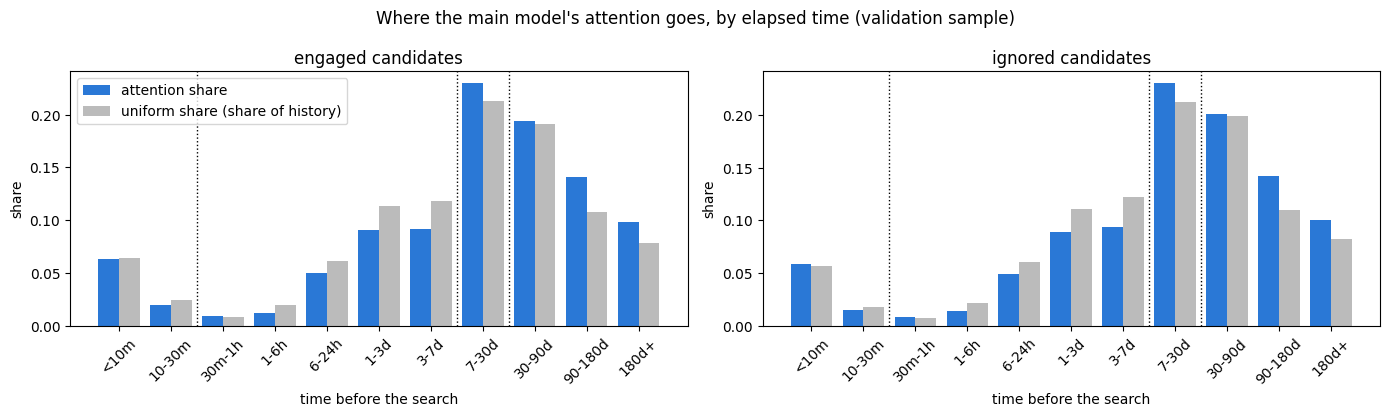

  uploaded attn_share_by_time_uall_w50-30-20_r5.png -> My Drive/BT4222_step3_attention
  uploaded attn_weights_time_uall_w50-30-20_r5.csv -> My Drive/BT4222_step3_attention
  uploaded attn_weights_type_uall_w50-30-20_r5.csv -> My Drive/BT4222_step3_attention
  uploaded attn_weights_match_uall_w50-30-20_r5.csv -> My Drive/BT4222_step3_attention
  uploaded attn_weights_none_slot_uall_w50-30-20_r5.csv -> My Drive/BT4222_step3_attention


In [15]:
def share_table(key, names, offset):
    rows = []
    for i, nm in enumerate(names):
        r = {key: nm}
        for g in ["engaged", "ignored"]:
            a = ACC[g]; att = a[key][i + offset] / a["n"]; uni = a[f"{key}_u"][i + offset] / a["n"]
            r[f"attention share ({g})"] = att; r[f"uniform share ({g})"] = uni; r[f"lift ({g})"] = att / uni if uni else np.nan
        rows.append(r)
    return pd.DataFrame(rows).set_index(key)

T_TIME = share_table("time", TIME_NAMES, 1)
T_TYPE = share_table("type", TYPE_NAMES, 1)
T_MATCH = share_table("match", ["exact product", "same shop", "same brand", "same cate3"], 0)
fmt3 = lambda t: t.style.format("{:.3f}")
print("1. Attention by time before the search"); display(fmt3(T_TIME))
print("2. Attention by action type"); display(fmt3(T_TYPE))
print("4. Attention on past actions that match the candidate (a past action can match on several)"); display(fmt3(T_MATCH))

hl_seg = pd.cut(U.user_hist_len.values[NONE_U.user.values], [-1, 4, 100, 10**9], labels=["<5 actions", "5-100", "100+"])
T_NONE = NONE_U.groupby(hl_seg, observed=True)[["none_engaged", "none_ignored"]].mean()
T_NONE.index = T_NONE.index.astype(str)
T_NONE.loc["all"] = [np.mean(ACC["engaged"]["none"]), np.mean(ACC["ignored"]["none"])]
print("3. Mean weight on the 'none of these' slot"); display(fmt3(T_NONE))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
x = np.arange(len(TIME_NAMES))
for i, g in enumerate(["engaged", "ignored"]):
    ax[i].bar(x - 0.2, T_TIME[f"attention share ({g})"], 0.4, label="attention share", color="#2a78d6")
    ax[i].bar(x + 0.2, T_TIME[f"uniform share ({g})"], 0.4, label="uniform share (share of history)", color="#bbbbbb")
    ax[i].set_xticks(x); ax[i].set_xticklabels(TIME_NAMES, rotation=45); ax[i].set_title(f"{g} candidates")
    ax[i].set_xlabel("time before the search"); ax[i].set_ylabel("share")
    for e in [1.5, 6.5, 7.5]:                             # 30-minute session gap; 7- and 90-day retention cutoffs
        ax[i].axvline(e, color="k", ls=":", lw=1)
ax[0].legend()
plt.suptitle("Where the main model's attention goes, by elapsed time (validation sample)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/attn_share_by_time_{DATA_TAG}.png", dpi=150); plt.show()

for t, n in [(T_TIME, "time"), (T_TYPE, "type"), (T_MATCH, "match"), (T_NONE, "none_slot")]:
    t.to_csv(f"{OUT_DIR}/attn_weights_{n}_{DATA_TAG}.csv")
save_to_drive(f"attn_share_by_time_{DATA_TAG}.png", *[f"attn_weights_{n}_{DATA_TAG}.csv" for n in ["time", "type", "match", "none_slot"]])

In [16]:
print("Case studies: an engaged candidate and the 5 past actions it attended to most")
for c in CASES:
    display(c.style.format({"weight": "{:.3f}", "none-slot weight": "{:.3f}"}))

Case studies: an engaged candidate and the 5 past actions it attended to most


,user,candidate label,action,type,time before search,exact product,same shop,same brand,same cate3,weight,none-slot weight
0,239,1,12,CART,<10m,False,False,False,False,0.080,0.416
1,239,1,3,CART,30-90d,False,False,False,False,0.051,0.416
2,239,1,9,CLICK,<10m,False,False,False,False,0.048,0.416
3,239,1,10,CLICK,<10m,False,False,False,False,0.048,0.416
4,239,1,11,CLICK,<10m,False,False,False,False,0.043,0.416


,user,candidate label,action,type,time before search,exact product,same shop,same brand,same cate3,weight,none-slot weight
0,309,2,32,ORD,7-30d,False,False,False,False,0.037,0.174
1,309,2,48,CART,7-30d,False,False,False,False,0.035,0.174
2,309,2,49,CART,7-30d,False,False,False,False,0.035,0.174
3,309,2,29,CART,7-30d,False,False,False,False,0.031,0.174
4,309,2,31,CART,7-30d,False,False,False,False,0.031,0.174


,user,candidate label,action,type,time before search,exact product,same shop,same brand,same cate3,weight,none-slot weight
0,324,1,17,CART,7-30d,False,False,False,False,0.045,0.295
1,324,1,25,CART,7-30d,False,False,False,False,0.040,0.295
2,324,1,27,CART,7-30d,False,False,False,False,0.040,0.295
3,324,1,26,CART,7-30d,False,False,False,False,0.040,0.295
4,324,1,29,CART,7-30d,False,False,False,False,0.040,0.295


## 12. Ablations: where does the gain come from?

Each ablation changes **one** thing relative to the main model (b), with the same rows, seed and early stopping. They run in this order; each cell uploads its results as soon as it finishes, so stopping early (or a disconnect) keeps the finished ones.

| Order | Run | What changes | What it answers |
|---|---|---|---|
| 1 | `meanpool` | candidate-aware attention → plain average of the history (like team 3's pooling) | does attention to *the candidate* matter? |
| 2 | `pure` (a) | the 65 features removed | how far does attention alone get? A fair comparison with team 3's neural model |
| 3 | `last100` | per-window caps → plain last 100 actions | is the per-window cap backed by our own result? (a tie also backs it) |
| 4 | `featonly` | history branch removed, only the 65 features | only if (b) trails LightGBM: is the gap the network or the attention? |
| 5 | `main_din`, `pure_din` | softmax + "none" slot → DIN's unnormalised weights | stretch: does normalisation matter? |

Expect (a) to score well below LightGBM: popularity, LightGBM's strongest signal, is in the 65 features, not the history. Softmax also hides some interest intensity (1 vs 50 relevant actions can look alike), which costs (a) more than (b); this may understate (a). In (b) the 65 features already see the full history, so the history cap only changes the attention branch, and a small difference or a tie is likely.

In [17]:
run_variant("meanpool", arch="hybrid", mode="meanpool", seq_name="win", prod_attrs=CATE_ONLY);

[meanpool] epoch 1: loss 0.2539 | val Hit@10 0.7038 | val NDCG@10 0.3985 | 8s | best so far
  uploaded attn_meanpool_uall_w50-30-20_r5_best.pt -> My Drive/BT4222_step3_attention
[meanpool] epoch 2: loss 0.2453 | val Hit@10 0.7064 | val NDCG@10 0.4013 | 7s | best so far
  uploaded attn_meanpool_uall_w50-30-20_r5_best.pt -> My Drive/BT4222_step3_attention
[meanpool] epoch 3: loss 0.2437 | val Hit@10 0.7086 | val NDCG@10 0.4040 | 8s | best so far
  uploaded attn_meanpool_uall_w50-30-20_r5_best.pt -> My Drive/BT4222_step3_attention
[meanpool] epoch 4: loss 0.2424 | val Hit@10 0.7097 | val NDCG@10 0.4047 | 8s | best so far
  uploaded attn_meanpool_uall_w50-30-20_r5_best.pt -> My Drive/BT4222_step3_attention
[meanpool] epoch 5: loss 0.2415 | val Hit@10 0.7108 | val NDCG@10 0.4053 | 8s | best so far
  uploaded attn_meanpool_uall_w50-30-20_r5_best.pt -> My Drive/BT4222_step3_attention
[meanpool] epoch 6: loss 0.2406 | val Hit@10 0.7112 | val NDCG@10 0.4053 | 8s
[meanpool] epoch 7: loss 0.2400 

,slates,hit@10,ndcg@10,mrr,p@1,hit@10 95% CI,ndcg@10 95% CI
model,,,,,,,
"meanpool: train (10,000 train_eval users)","10,000",0.7167,0.4085,0.4071,0.2609,0.707 to 0.725,0.401 to 0.415
meanpool: validation,"17,172",0.7140,0.4074,0.4064,0.2634,0.707 to 0.721,0.402 to 0.413


[meanpool] best epoch 7 | 103s this session
  uploaded attn_ablation_scores_val.parquet -> My Drive/BT4222_step3_attention


In [18]:
run_variant("pure", arch="pure", mode="softmax_slot", seq_name="win", prod_attrs=CATE_ONLY);

[pure] epoch 1: loss 0.3005 | val Hit@10 0.2846 | val NDCG@10 0.1303 | 24s | best so far
  uploaded attn_pure_uall_w50-30-20_r5_best.pt -> My Drive/BT4222_step3_attention
[pure] epoch 2: loss 0.2923 | val Hit@10 0.3110 | val NDCG@10 0.1567 | 24s | best so far
  uploaded attn_pure_uall_w50-30-20_r5_best.pt -> My Drive/BT4222_step3_attention
[pure] epoch 3: loss 0.2863 | val Hit@10 0.3125 | val NDCG@10 0.1572 | 24s | best so far
  uploaded attn_pure_uall_w50-30-20_r5_best.pt -> My Drive/BT4222_step3_attention
[pure] epoch 4: loss 0.2853 | val Hit@10 0.3165 | val NDCG@10 0.1588 | 24s | best so far
  uploaded attn_pure_uall_w50-30-20_r5_best.pt -> My Drive/BT4222_step3_attention
[pure] epoch 5: loss 0.2848 | val Hit@10 0.3144 | val NDCG@10 0.1585 | 24s
[pure] epoch 6: loss 0.2843 | val Hit@10 0.3152 | val NDCG@10 0.1582 | 24s
[pure] epoch 7: loss 0.2840 | val Hit@10 0.3181 | val NDCG@10 0.1593 | 24s | best so far
  uploaded attn_pure_uall_w50-30-20_r5_best.pt -> My Drive/BT4222_step3_atten

,slates,hit@10,ndcg@10,mrr,p@1,hit@10 95% CI,ndcg@10 95% CI
model,,,,,,,
"pure: train (10,000 train_eval users)","10,000",0.3304,0.1677,0.1938,0.1160,0.322 to 0.340,0.162 to 0.173
pure: validation,"17,172",0.3180,0.1596,0.1880,0.1142,0.311 to 0.325,0.155 to 0.164


[pure] best epoch 12 | 400s this session
  uploaded attn_ablation_scores_val.parquet -> My Drive/BT4222_step3_attention


In [19]:
run_variant("last100", arch="hybrid", mode="softmax_slot", seq_name="last", prod_attrs=CATE_ONLY);

[last100] epoch 1: loss 0.2550 | val Hit@10 0.7041 | val NDCG@10 0.3991 | 25s | best so far
  uploaded attn_last100_uall_w50-30-20_r5_best.pt -> My Drive/BT4222_step3_attention
[last100] epoch 2: loss 0.2456 | val Hit@10 0.7067 | val NDCG@10 0.4015 | 25s | best so far
  uploaded attn_last100_uall_w50-30-20_r5_best.pt -> My Drive/BT4222_step3_attention
[last100] epoch 3: loss 0.2439 | val Hit@10 0.7091 | val NDCG@10 0.4046 | 25s | best so far
  uploaded attn_last100_uall_w50-30-20_r5_best.pt -> My Drive/BT4222_step3_attention
[last100] epoch 4: loss 0.2425 | val Hit@10 0.7121 | val NDCG@10 0.4053 | 24s | best so far
  uploaded attn_last100_uall_w50-30-20_r5_best.pt -> My Drive/BT4222_step3_attention
[last100] epoch 5: loss 0.2416 | val Hit@10 0.7123 | val NDCG@10 0.4052 | 24s
[last100] epoch 6: loss 0.2406 | val Hit@10 0.7103 | val NDCG@10 0.4052 | 24s
[last100] epoch 7: loss 0.2400 | val Hit@10 0.7119 | val NDCG@10 0.4054 | 24s | best so far
  uploaded attn_last100_uall_w50-30-20_r5_be

,slates,hit@10,ndcg@10,mrr,p@1,hit@10 95% CI,ndcg@10 95% CI
model,,,,,,,
"last100: train (10,000 train_eval users)","10,000",0.7187,0.4098,0.4089,0.2632,0.710 to 0.727,0.402 to 0.416
last100: validation,"17,172",0.7117,0.4062,0.4054,0.2608,0.705 to 0.719,0.401 to 0.412


[last100] best epoch 9 | 328s this session
  uploaded attn_ablation_scores_val.parquet -> My Drive/BT4222_step3_attention


In [20]:
main_m, lg_m = PER_VAL["Attention (b category-only, ours)"], PER_VAL["LightGBM BCE"]
trails = main_m["hit@10"].mean() < lg_m["hit@10"].mean() or main_m["ndcg@10"].mean() < lg_m["ndcg@10"].mean()
if RUN_FEATONLY is True or (RUN_FEATONLY == "auto" and trails):
    print(f"main model {'trails' if trails else 'does not trail'} LightGBM: running features-only")
    run_variant("featonly", arch="featonly", seq_name="win")
else:
    print("features-only skipped: the main model does not trail LightGBM on Hit@10 or NDCG@10")

main model trails LightGBM: running features-only
[featonly] epoch 1: loss 0.2557 | val Hit@10 0.7070 | val NDCG@10 0.3993 | 5s | best so far
  uploaded attn_featonly_uall_w50-30-20_r5_best.pt -> My Drive/BT4222_step3_attention
[featonly] epoch 2: loss 0.2454 | val Hit@10 0.7120 | val NDCG@10 0.4035 | 5s | best so far
  uploaded attn_featonly_uall_w50-30-20_r5_best.pt -> My Drive/BT4222_step3_attention
[featonly] epoch 3: loss 0.2440 | val Hit@10 0.7120 | val NDCG@10 0.4052 | 5s | best so far
  uploaded attn_featonly_uall_w50-30-20_r5_best.pt -> My Drive/BT4222_step3_attention
[featonly] epoch 4: loss 0.2432 | val Hit@10 0.7141 | val NDCG@10 0.4072 | 5s | best so far
  uploaded attn_featonly_uall_w50-30-20_r5_best.pt -> My Drive/BT4222_step3_attention
[featonly] epoch 5: loss 0.2426 | val Hit@10 0.7141 | val NDCG@10 0.4067 | 5s
[featonly] epoch 6: loss 0.2422 | val Hit@10 0.7160 | val NDCG@10 0.4073 | 5s | best so far
  uploaded attn_featonly_uall_w50-30-20_r5_best.pt -> My Drive/BT422

,slates,hit@10,ndcg@10,mrr,p@1,hit@10 95% CI,ndcg@10 95% CI
model,,,,,,,
"featonly: train (10,000 train_eval users)","10,000",0.7170,0.4102,0.4095,0.2648,0.708 to 0.726,0.403 to 0.417
featonly: validation,"17,172",0.7181,0.4097,0.4073,0.2619,0.711 to 0.725,0.404 to 0.415


[featonly] best epoch 14 | 120s this session
  uploaded attn_ablation_scores_val.parquet -> My Drive/BT4222_step3_attention


In [21]:
# RUN_STRETCH = True
if RUN_STRETCH:
    run_variant("main_din", arch="hybrid", mode="din", seq_name="win", prod_attrs=CATE_ONLY)
    run_variant("pure_din", arch="pure", mode="din", seq_name="win", prod_attrs=CATE_ONLY)
else:
    print("stretch 2x2 (DIN's unnormalised weights) skipped: set RUN_STRETCH = True to run it")

stretch 2x2 (DIN's unnormalised weights) skipped: set RUN_STRETCH = True to run it


**RESULT: ablations.** Each row: the ablation minus the main model on validation (negative = the removed part helped), paired bootstrap over users. `pure` is also compared with team 3's model (scored by P(engaged), step 2), since both are neural models on history and product data. For the cold-product segment, the no-attention control is compared with the main model.

In [22]:
ABL_NAMES = {"meanpool": "No-attention control (mean pool)", "pure": "Pure sequence (a)", "last100": "History cap: last 100",
             "featonly": "Features only", "main_din": "(b) with DIN weights", "pure_din": "(a) with DIN weights"}

for n, label in ABL_NAMES.items():
    if n in RUNS:
        PV[score_col(n)] = PV[["user", "wid"]].merge(RUNS[n]["scores"][["user", "wid", score_col(n)]], on=["user", "wid"],
                                                       how="left", validate="one_to_one")[score_col(n)].values
        PER_VAL_ALL[label] = evaluate(PV, PV[score_col(n)])
rows = []
for n, label in ABL_NAMES.items():
    if label not in PER_VAL_ALL:
        continue
    t = paired(label, "Attention (b category-only, ours)", metrics=["hit@10", "ndcg@10"])
    for m in ["hit@10", "ndcg@10"]:
        rows.append({"ablation": label, "metric": m, "ablation score": t.loc[m, label], "main (b)": t.loc[m, "Attention (b category-only, ours)"],
                     "ablation minus main": t.loc[m, "difference"], "95% CI": t.loc[m, "95% CI"], "real?": t.loc[m, "real?"]})
ABL = pd.DataFrame(rows).set_index(["ablation", "metric"])
display(ABL.style.format({c: "{:.4f}" for c in ["ablation score", "main (b)", "ablation minus main"]}))
ABL.to_csv(f"{OUT_DIR}/attn_ablations_{DATA_TAG}.csv")
if "Pure sequence (a)" in PER_VAL_ALL:
    t3 = BASELINE_NAMES["score_t3_pengaged"]
    print(f"\nPure sequence (a) minus {t3}:")
    display(paired("Pure sequence (a)", t3).style.format({c: "{:.4f}" for c in ["Pure sequence (a)", t3, "difference"]}))
if "No-attention control (mean pool)" in PER_VAL_ALL:
    print("\nNDCG@10 by engaged product: main (b) vs no-attention control")
    display(seg_table("Attention (b category-only, ours)", "No-attention control (mean pool)", "engaged product").style.format(
        {c: "{:.4f}" for c in ["Attention (b category-only, ours)", "No-attention control (mean pool)", "difference"]}))
save_to_drive(f"attn_ablations_{DATA_TAG}.csv")


Pure sequence (a) minus Team 3 NCF (fixed: P(engaged)):


,Pure sequence (a),Team 3 NCF (fixed: P(engaged)),difference,95% CI,real?
metric,,,,,
hit@10,0.3180,0.4507,-0.1327,-0.1412 to -0.1233,yes
ndcg@10,0.1596,0.2187,-0.0591,-0.0646 to -0.0536,yes
mrr,0.1880,0.2244,-0.0363,-0.0424 to -0.0306,yes
p@1,0.1142,0.1165,-0.0023,-0.0086 to +0.0039,no (CI includes 0)



NDCG@10 by engaged product: main (b) vs no-attention control


,slates,"Attention (b category-only, ours)",No-attention control (mean pool),difference,95% CI
engaged product,,,,,
all cold,3117,0.1921,0.1942,-0.0021,-0.005 to +0.001
some warm,14055,0.4540,0.4547,-0.0007,-0.002 to +0.001


  uploaded attn_ablations_uall_w50-30-20_r5.csv -> My Drive/BT4222_step3_attention


## 13. Test (final run only)

Runs only when `RUN_TEST = True`, after the group has picked the final model. Only the main model (b) is scored on test, once, from its saved checkpoint. Ablations stay validation-only.

In [23]:
if RUN_TEST:
    TST = user_groups(KM.split.values == 2)
    st = rows_df(TST); st["score_attn"] = score_rows(RUNS["main"]["model"], TST, SEQS["win"])
    f = "attn_scores_test.parquet" if FULL else f"attn_scores_test_{DATA_TAG}.parquet"
    st.to_parquet(f"{OUT_DIR}/{f}", index=False)
    res_test = pd.DataFrame([summarise(evaluate(st, st.score_attn), "Attention (b, ours): test")]).set_index("model")
    display(res_test.style.format(FMT))
    res_test.to_csv(f"{OUT_DIR}/attn_test_results_{DATA_TAG}.csv")
    save_to_drive(f, f"attn_test_results_{DATA_TAG}.csv")
else:
    print("RUN_TEST is False: test users not scored.")

,slates,hit@10,ndcg@10,mrr,p@1,hit@10 95% CI,ndcg@10 95% CI
model,,,,,,,
"Attention (b, ours): test","17,176",0.7065,0.4038,0.4035,0.2613,0.700 to 0.713,0.399 to 0.409


  uploaded attn_scores_test.parquet -> My Drive/BT4222_step3_attention
  uploaded attn_test_results_uall_w50-30-20_r5.csv -> My Drive/BT4222_step3_attention


## 14. Findings

Full run 8 Nov 2026 (18:36–18:56). Main model (b): hybrid, category-only product embeddings (shop and brand dropped for overfitting). Validation 17,172 users, test 17,176, full slates. "Proven" = paired 95% bootstrap CI over users excludes 0.

- **Main model (b) vs LightGBM:** validation Hit@10 0.7130 vs BCE 0.7188 (−0.0059, CI −0.0093 to −0.0022) and LambdaRank 0.7231 (−0.0101, CI −0.0137 to −0.0064). NDCG@10 0.4065 vs 0.4146 (−0.0081, CI −0.0103 to −0.0060) and 0.4168 (−0.0103, CI −0.0124 to −0.0082). All proven: attention is below both LightGBM models.
- **vs best baseline:** above repeat → popularity, Hit@10 +0.0316 (CI +0.0266 to +0.0373), NDCG@10 +0.0208 (CI +0.0181 to +0.0236).
- **Train vs validation gap:** Hit@10 0.7174 vs 0.7130 (0.004); NDCG@10 0.4107 vs 0.4065 (0.004). Smaller than LightGBM BCE (0.015 / 0.013), so little overfitting.
- **Does candidate-aware attention matter?** Mean-pool control minus main: Hit@10 +0.0010 (CI −0.0021 to +0.0038), NDCG@10 +0.0009 (CI −0.0005 to +0.0023). A tie: attending to the candidate adds nothing over a plain average of the history.
- **Where the gap to LightGBM comes from:** features-only (history branch removed) minus main: Hit@10 +0.0051 (CI +0.0016 to +0.0082), NDCG@10 +0.0032 (CI +0.0015 to +0.0050), both proven. The history branch slightly hurts. Features-only reaches Hit@10 0.7181 / NDCG@10 0.4097 vs BCE 0.7188 / 0.4146 (means only, not paired): it closes most of the Hit@10 gap, less of the NDCG@10 gap.
- **Attention alone (a):** Hit@10 0.3180, NDCG@10 0.1596 (−0.3949 Hit@10 vs main). Below team 3's NCF scored by P(engaged): Hit@10 −0.1327 (CI −0.1412 to −0.1233), NDCG@10 −0.0591 (CI −0.0646 to −0.0536); P@1 a tie. The signal is in the 65 features (popularity), not the history sequence.
- **History cap:** last 100 minus per-window: Hit@10 −0.0012 (CI −0.0042 to +0.0016), NDCG@10 −0.0003 (CI −0.0017 to +0.0011). A tie, which backs the per-window cap.
- **Segments (NDCG@10, attention minus BCE):** <5 actions −0.0128 (CI −0.023 to −0.003), 5–100 −0.0067 (CI −0.010 to −0.004), 100+ −0.0095 (CI −0.013 to −0.006); all-cold slates −0.0058 (CI −0.011 to −0.001), some-warm −0.0087 (CI −0.011 to −0.006). Attention is below BCE in every group, including long histories and cold products. On all-cold slates it ties the mean-pool control (−0.0021, CI −0.005 to +0.001). Step 4's finer bins agree: below LambdaRank in every history bin.
- **What attention looks at (descriptive, not causal):**
    - Time: more weight on old actions (lift 1.31 at 90–180 d, 1.25 at 180 d+), less on 1 h–7 d (0.61–0.82).
    - Action type: orders (1.21) and carts (1.15) over clicks (0.66). Same pattern as time: past 90 days only orders are logged (F4).
    - "None" slot: weight 0.76 for <5 actions, 0.24 for 5–100, 0.09 for 100+, so it personalises less when history is thin. Engaged vs ignored: 0.189 vs 0.197.
    - Matches: no extra weight on the exact product (lift 0.80), same shop (0.88), brand (0.89) or level-3 category (0.88). Attention does not find the matches LightGBM's features hand-code.
    - Lifts are almost the same for engaged and ignored candidates: weights follow an action's age and type, not the candidate. This fits the mean-pool tie.
- **Test (scored once):** Hit@10 0.7065, NDCG@10 0.4038, MRR 0.4035, P@1 0.2613 (LambdaRank 0.7190 / 0.4146 / 0.4145 / 0.2707). Means only; no paired CI on test.
- **Decision:** attention is reported as a tested alternative, not the final model. LambdaRank stays final.